# Chương 4 — Khám phá và tiền xử lý dữ liệu

Notebook đi kèm giáo trình **Học máy cơ bản với Python** (Lê Nhật Tùng).

**Cách dùng trên Google Colab**

1. Mở <https://colab.research.google.com> → **File** → **Upload notebook** → chọn file này
   (hoặc mở từ Google Drive bằng *Open with → Google Colaboratory*).
2. Chạy lần lượt từng ô từ trên xuống bằng **Shift + Enter**. Các ô sau dùng lại biến của ô trước.
3. Gặp lỗi lạ: **Runtime → Restart session and run all**.

Mỗi ô mã bắt đầu bằng dòng `# ô ten_o` — đó là tên ô in ở đầu mỗi khung mã trong sách,
giúp bạn đối chiếu với giáo trình. Kết quả bên dưới mỗi ô là kết quả chạy mẫu; máy bạn có thể
khác rất nhỏ ở chữ số thập phân cuối nếu phiên bản thư viện khác.

> Hãy **tự gõ lại mã** vào một notebook trống trước khi xem lời giải ở đây — đó là cách học nhanh nhất.

> Chương này tải bộ dữ liệu bằng `seaborn.load_dataset(...)`, cần kết nối Internet (Colab luôn có sẵn).


In [1]:
# ô import_thu_vien
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 85)

## 4.2 Làm quen với dữ liệu Titanic

In [2]:
# ô titanic_load
titanic = sns.load_dataset("titanic")
print("Kích thước:", titanic.shape)
print(titanic.head())

Kích thước: (891, 15)
   survived  pclass     sex   age  sibsp  parch     fare embarked  class    who  \
0         0       3    male  22.0      1      0   7.2500        S  Third    man   
1         1       1  female  38.0      1      0  71.2833        C  First  woman   
2         1       3  female  26.0      0      0   7.9250        S  Third  woman   
3         1       1  female  35.0      1      0  53.1000        S  First  woman   
4         0       3    male  35.0      0      0   8.0500        S  Third    man   

   adult_male deck  embark_town alive  alone  
0        True  NaN  Southampton    no  False  
1       False    C    Cherbourg   yes  False  
2       False  NaN  Southampton   yes   True  
3       False    C  Southampton   yes  False  
4        True  NaN  Southampton    no   True  


In [3]:
# ô titanic_info
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


## 4.3 Khám phá dữ liệu (EDA)

In [4]:
# ô eda_nhan
print(titanic["survived"].value_counts())
print("Tỉ lệ sống sót:", round(titanic["survived"].mean(), 4))

survived
0    549
1    342
Name: count, dtype: int64
Tỉ lệ sống sót: 0.3838


In [5]:
# ô eda_thieu
so_thieu = titanic.isna().sum()
ti_le_thieu = (so_thieu / len(titanic) * 100).round(1)
bang_thieu = pd.DataFrame({"so_o_trong": so_thieu, "ti_le_%": ti_le_thieu})
print(bang_thieu[bang_thieu["so_o_trong"] > 0])

             so_o_trong  ti_le_%
age                 177     19.9
embarked              2      0.2
deck                688     77.2
embark_town           2      0.2


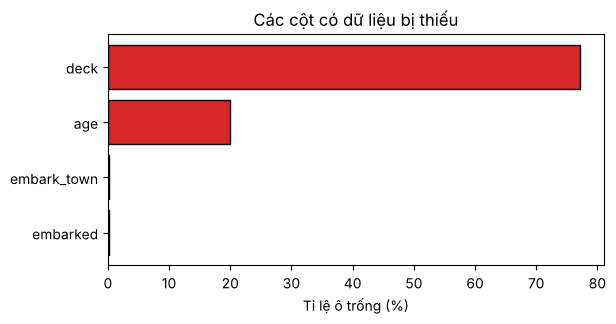

In [6]:
# ô eda_thieu_hinh
bang_thieu = bang_thieu[bang_thieu["so_o_trong"] > 0].sort_values("ti_le_%")
plt.figure(figsize=(6.4, 3))
plt.barh(bang_thieu.index, bang_thieu["ti_le_%"], color="tab:red", edgecolor="k")
plt.xlabel("Tỉ lệ ô trống (%)")
plt.title("Các cột có dữ liệu bị thiếu")
plt.show()

In [7]:
# ô eda_describe
print(titanic[["age", "fare", "sibsp", "parch"]].describe().round(2))

          age    fare   sibsp   parch
count  714.00  891.00  891.00  891.00
mean    29.70   32.20    0.52    0.38
std     14.53   49.69    1.10    0.81
min      0.42    0.00    0.00    0.00
25%     20.12    7.91    0.00    0.00
50%     28.00   14.45    0.00    0.00
75%     38.00   31.00    1.00    0.00
max     80.00  512.33    8.00    6.00


In [8]:
# ô eda_nhom
print(titanic.groupby("sex")["survived"].mean().round(3))
print(titanic.groupby("pclass")["survived"].mean().round(3))

sex
female    0.742
male      0.189
Name: survived, dtype: float64
pclass
1    0.630
2    0.473
3    0.242
Name: survived, dtype: float64


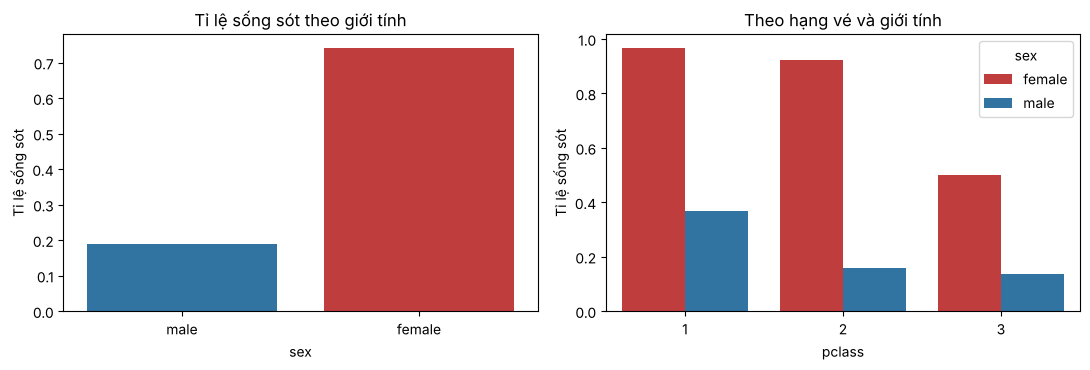

In [9]:
# ô eda_nhom_hinh
mau_gioi = {"male": "tab:blue", "female": "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.barplot(data=titanic, x="sex", y="survived", ax=ax[0], errorbar=None,
            hue="sex", palette=mau_gioi, legend=False)
ax[0].set_title("Tỉ lệ sống sót theo giới tính"); ax[0].set_ylabel("Tỉ lệ sống sót")
sns.barplot(data=titanic, x="pclass", y="survived", hue="sex", ax=ax[1], errorbar=None,
            palette=mau_gioi)
ax[1].set_title("Theo hạng vé và giới tính"); ax[1].set_ylabel("Tỉ lệ sống sót")
plt.tight_layout()
plt.show()

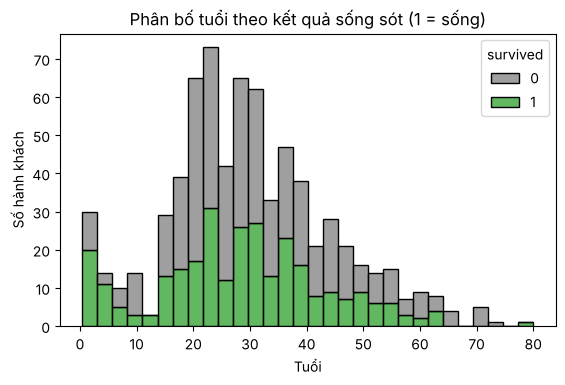

In [10]:
# ô eda_tuoi
plt.figure(figsize=(6.4, 3.8))
sns.histplot(data=titanic, x="age", hue="survived", bins=30, multiple="stack",
             palette=["tab:gray", "tab:green"])
plt.xlabel("Tuổi"); plt.ylabel("Số hành khách")
plt.title("Phân bố tuổi theo kết quả sống sót (1 = sống)")
plt.show()

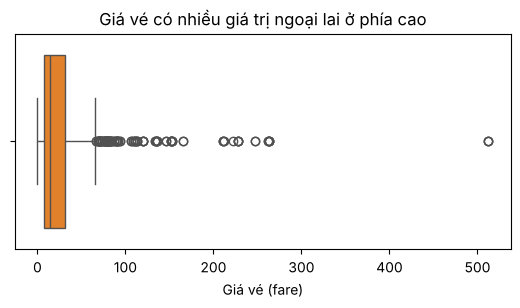

In [11]:
# ô eda_fare
plt.figure(figsize=(6.4, 2.8))
sns.boxplot(x=titanic["fare"], color="tab:orange")
plt.xlabel("Giá vé (fare)")
plt.title("Giá vé có nhiều giá trị ngoại lai ở phía cao")
plt.show()

## 4.4 Làm sạch dữ liệu

In [12]:
# ô lam_sach_cot
print(pd.crosstab(titanic["survived"], titanic["alive"]))
cot_bo = ["alive", "class", "who", "adult_male", "embark_town", "deck"]
df = titanic.drop(columns=cot_bo)
print("Còn lại", df.shape[1], "cột:", df.columns.tolist())

alive      no  yes
survived          
0         549    0
1           0  342
Còn lại 9 cột: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'alone']


In [13]:
# ô lam_sach_trung
print("Số dòng trùng lặp:", df.duplicated().sum())

Số dòng trùng lặp: 111


In [14]:
# ô thieu_xoa
print("Số dòng ban đầu        :", len(df))
print("Xóa mọi dòng có ô trống:", len(df.dropna()))

Số dòng ban đầu        : 891
Xóa mọi dòng có ô trống: 712


In [15]:
# ô thieu_dien
df = df.copy()
trung_vi_tuoi = df["age"].median()
yeu_vi_cang = df["embarked"].mode()[0]
print("Trung vị tuổi:", trung_vi_tuoi, " Cảng phổ biến nhất:", yeu_vi_cang)
df["age"] = df["age"].fillna(trung_vi_tuoi)
df["embarked"] = df["embarked"].fillna(yeu_vi_cang)
print("Số ô trống còn lại:", df.isna().sum().sum())

Trung vị tuổi: 28.0  Cảng phổ biến nhất: S
Số ô trống còn lại: 0


In [16]:
# ô thieu_theo_nhom
goc = titanic.copy()
tuoi_theo_nhom = goc.groupby(["pclass", "sex"])["age"].median()
print(tuoi_theo_nhom)

pclass  sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: age, dtype: float64


In [17]:
# ô ngoai_lai
q1, q3 = df["fare"].quantile([0.25, 0.75])
iqr = q3 - q1
can_tren = q3 + 1.5 * iqr
print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}, cận trên = {can_tren:.2f}")
print("Số vé ngoại lai:", (df["fare"] > can_tren).sum())

Q1 = 7.91, Q3 = 31.00, IQR = 23.09, cận trên = 65.63
Số vé ngoại lai: 116


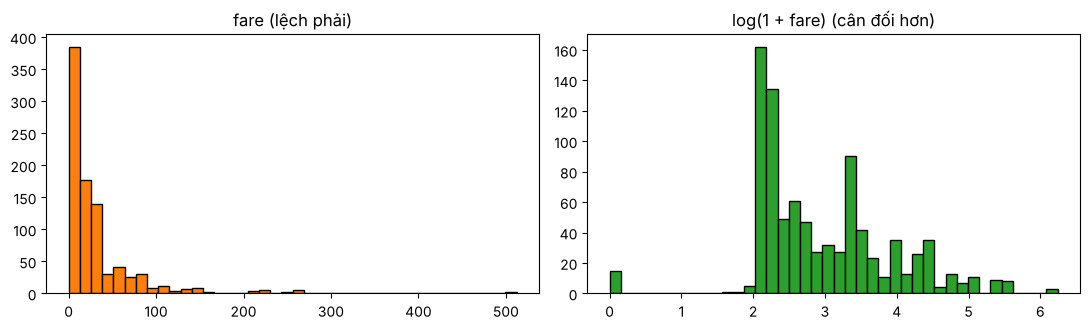

In [18]:
# ô log_fare
log_fare = np.log1p(df["fare"])          # log(1 + fare), tránh log(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(df["fare"], bins=40, color="tab:orange", edgecolor="k")
ax[0].set_title("fare (lệch phải)")
ax[1].hist(log_fare, bins=40, color="tab:green", edgecolor="k")
ax[1].set_title("log(1 + fare) (cân đối hơn)")
plt.tight_layout()
plt.show()

## 4.5 Mã hóa biến phân loại

In [19]:
# ô ma_hoa_nhi_phan
df["sex"] = df["sex"].map({"male": 0, "female": 1})
print(df["sex"].value_counts())

sex
0    577
1    314
Name: count, dtype: int64


In [20]:
# ô ma_hoa_onehot
vi_du = pd.DataFrame({"embarked": ["S", "C", "Q", "S"]})
print(pd.get_dummies(vi_du, columns=["embarked"], dtype=int))

   embarked_C  embarked_Q  embarked_S
0           0           0           1
1           1           0           0
2           0           1           0
3           0           0           1


In [21]:
# ô ma_hoa_titanic
df = pd.get_dummies(df, columns=["embarked"], dtype=int)
df["alone"] = df["alone"].astype(int)
print(df.head(3))

   survived  pclass  sex   age  sibsp  parch     fare  alone  embarked_C  \
0         0       3    0  22.0      1      0   7.2500      0           0   
1         1       1    1  38.0      1      0  71.2833      0           1   
2         1       3    1  26.0      0      0   7.9250      1           0   

   embarked_Q  embarked_S  
0           0           1  
1           0           0  
2           0           1  


## 4.6 Tạo đặc trưng mới

In [22]:
# ô dac_trung_moi
df["family_size"] = df["sibsp"] + df["parch"] + 1
print(df.groupby("family_size")["survived"].agg(["count", "mean"]).round(3))

             count   mean
family_size              
1              537  0.304
2              161  0.553
3              102  0.578
4               29  0.724
5               15  0.200
6               22  0.136
7               12  0.333
8                6  0.000
11               7  0.000


## 4.7 Co giãn đặc trưng

In [23]:
# ô co_gian_tay
x = np.array([20.0, 30.0, 50.0])
x_minmax = (x - x.min()) / (x.max() - x.min())
x_z = (x - x.mean()) / x.std()
print("Min-max :", x_minmax.round(4))
print("Z-score :", x_z.round(4))
print("Z-score có trung bình", round(x_z.mean(), 4), "và độ lệch chuẩn", round(x_z.std(), 4))

Min-max : [0.     0.3333 1.    ]
Z-score : [-1.069  -0.2673  1.3363]
Z-score có trung bình -0.0 và độ lệch chuẩn 1.0


In [24]:
# ô co_gian_sklearn
from sklearn.preprocessing import MinMaxScaler, StandardScaler
cot_so = df[["age", "fare"]]
print(cot_so.describe().loc[["mean", "std", "min", "max"]].round(2))
chuan = StandardScaler().fit_transform(cot_so)
print("Sau StandardScaler: trung bình", chuan.mean(axis=0).round(4),
      " độ lệch chuẩn", chuan.std(axis=0).round(4))

        age    fare
mean  29.36   32.20
std   13.02   49.69
min    0.42    0.00
max   80.00  512.33
Sau StandardScaler: trung bình [0. 0.]  độ lệch chuẩn [1. 1.]


In [25]:
# ô wine_co_gian
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

knn = KNeighborsClassifier(n_neighbors=5)
print("Không co giãn :", round(knn.fit(X_train, y_train).score(X_test, y_test), 4))
for bo_co_gian in [MinMaxScaler(), StandardScaler()]:
    bo_co_gian.fit(X_train)                       # CHỈ học từ tập huấn luyện
    Xtr = bo_co_gian.transform(X_train)
    Xte = bo_co_gian.transform(X_test)            # dùng lại thông số đã học
    diem = knn.fit(Xtr, y_train).score(Xte, y_test)
    print(f"{type(bo_co_gian).__name__:14s}:", round(diem, 4))

Không co giãn : 0.7222
MinMaxScaler  : 0.963
StandardScaler: 0.9444


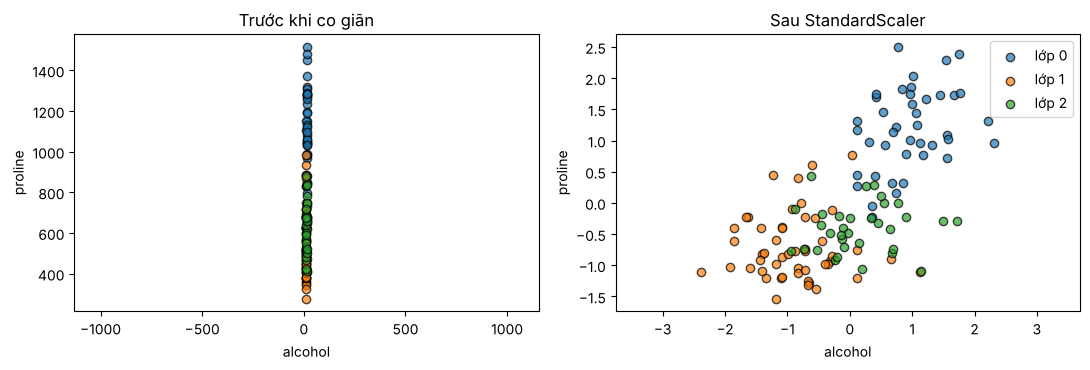

In [26]:
# ô wine_co_gian_hinh
cot = [0, 12]                                    # alcohol và proline
truoc = X_train[:, cot]
sau = StandardScaler().fit_transform(X_train)[:, cot]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, du_lieu, td in [(ax[0], truoc, "Trước khi co giãn"), (ax[1], sau, "Sau StandardScaler")]:
    for k, mau in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
        a.scatter(du_lieu[y_train == k, 0], du_lieu[y_train == k, 1], c=mau,
                  edgecolors="k", alpha=0.7, label=f"lớp {k}")
    a.set_xlabel("alcohol"); a.set_ylabel("proline"); a.set_title(td)
ax[0].set_aspect("equal", adjustable="datalim")
ax[1].set_aspect("equal", adjustable="datalim")
ax[1].legend()
plt.tight_layout()
plt.show()

## 4.8 Rò rỉ dữ liệu và quy trình hoàn chỉnh với Pipeline

In [27]:
# ô pipeline_titanic
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

data = sns.load_dataset("titanic")
X = data[["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]]
y = data["survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

cot_so = ["age", "sibsp", "parch", "fare", "pclass"]
cot_chu = ["sex", "embarked"]
xu_ly_so = Pipeline([("dien_thieu", SimpleImputer(strategy="median")),
                     ("co_gian", StandardScaler())])
xu_ly_chu = Pipeline([("dien_thieu", SimpleImputer(strategy="most_frequent")),
                      ("one_hot", OneHotEncoder(handle_unknown="ignore"))])
tien_xu_ly = ColumnTransformer([("so", xu_ly_so, cot_so),
                                ("chu", xu_ly_chu, cot_chu)])
mo_hinh = Pipeline([("tien_xu_ly", tien_xu_ly),
                    ("knn", KNeighborsClassifier(n_neighbors=7))])
mo_hinh.fit(X_train, y_train)
print("Accuracy trên tập kiểm tra:", round(mo_hinh.score(X_test, y_test), 4))

Accuracy trên tập kiểm tra: 0.7989


In [28]:
# ô pipeline_du_doan
khach_moi = pd.DataFrame([
    {"pclass": 1, "sex": "female", "age": 28, "sibsp": 0, "parch": 0, "fare": 80.0, "embarked": "C"},
    {"pclass": 3, "sex": "male", "age": None, "sibsp": 0, "parch": 0, "fare": 7.9, "embarked": "S"},
])
print(mo_hinh.predict(khach_moi))

[1 0]


## Thực hành 4.1: Chim cánh cụt Penguins

In [29]:
# ô lab_buoc1
peng = sns.load_dataset("penguins")
print(peng.shape)
print(peng.isna().sum())
print(peng["species"].value_counts())

(344, 7)
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


In [30]:
# ô lab_buoc2
X = peng.drop(columns="species")
y = peng["species"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
cot_so = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cot_chu = ["island", "sex"]
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (258, 6)  Test: (86, 6)


In [31]:
# ô lab_buoc3
for co_gian in [False, True]:
    buoc_so = [("dien_thieu", SimpleImputer(strategy="median"))]
    if co_gian:
        buoc_so.append(("co_gian", StandardScaler()))
    tien_xu_ly = ColumnTransformer([
        ("so", Pipeline(buoc_so), cot_so),
        ("chu", Pipeline([("dien_thieu", SimpleImputer(strategy="most_frequent")),
                          ("one_hot", OneHotEncoder(handle_unknown="ignore"))]), cot_chu)])
    mh = Pipeline([("tien_xu_ly", tien_xu_ly), ("knn", KNeighborsClassifier(n_neighbors=5))])
    mh.fit(X_train, y_train)
    print(f"Co giãn = {co_gian!s:5s}: accuracy = {mh.score(X_test, y_test):.4f}")

Co giãn = False: accuracy = 0.7791
Co giãn = True : accuracy = 0.9884


## Bài tập tự làm

Mức độ: ⭐ cơ bản, ⭐⭐ nâng cao, ⭐⭐⭐ thử thách. Viết lời giải vào ô mã trống ngay dưới mỗi bài.

**Bài 4.1.** ⭐ Với dữ liệu Titanic, tính tỉ lệ sống sót theo cảng lên tàu (`embarked`) và theo nhóm `alone`. Vẽ biểu đồ cột cho mỗi trường hợp và nêu nhận xét.

In [ ]:
# Lời giải Bài 4.1


**Bài 4.2.** ⭐ Tạo cột `nhom_tuoi` chia tuổi thành 4 nhóm: trẻ em (dưới 13), thiếu niên (13--19), người lớn (20--59), cao tuổi (từ 60) bằng `pd.cut`. Tính tỉ lệ sống sót của mỗi nhóm.

In [ ]:
# Lời giải Bài 4.2


**Bài 4.3.** ⭐ Với dữ liệu tips (Chương 2), mã hóa one-hot cột `day` và mã hóa nhị phân cột `smoker`. In 5 dòng đầu của bảng kết quả.

In [ ]:
# Lời giải Bài 4.3


**Bài 4.4.** ⭐ Tính tay rồi kiểm tra bằng `MinMaxScaler` và `StandardScaler` cho cột $(10, 20, 20, 30, 70)$. Nhận xét ảnh hưởng của giá trị 70 lên kết quả Min-Max.

In [ ]:
# Lời giải Bài 4.4


**Bài 4.5.** ⭐⭐ Điền tuổi bị thiếu trong Titanic bằng trung vị **theo nhóm** (`pclass`, `sex`). Gợi ý: `df.groupby(["pclass", "sex"])["age"].transform("median")`. So sánh phân bố tuổi (histogram) sau khi điền theo hai cách: trung vị chung và trung vị theo nhóm.

In [ ]:
# Lời giải Bài 4.5


**Bài 4.6.** ⭐⭐ Thêm đặc trưng `family_size` vào pipeline Titanic ở Mục 4.8 (tạo cột trước khi chia tập; vì sao việc này không gây rò rỉ?). Độ chính xác thay đổi thế nào?

In [ ]:
# Lời giải Bài 4.6


**Bài 4.7.** ⭐⭐ Trong pipeline Titanic, thử thay `StandardScaler` bằng `MinMaxScaler`, và thử $k = 3, 5, 7, 9, 11, 15$. Lập bảng kết quả và chọn cấu hình tốt nhất.

In [ ]:
# Lời giải Bài 4.7


**Bài 4.8.** ⭐⭐ Cố tình làm **sai**: với Wine, `fit` `StandardScaler` trên toàn bộ $X$ rồi mới chia tập và huấn luyện kNN. So sánh độ chính xác với cách làm đúng. Lặp lại thí nghiệm với 20 giá trị `random_state` khác nhau và tính chênh lệch trung bình. Rò rỉ trong trường hợp này lớn hay nhỏ? Vì sao?

In [ ]:
# Lời giải Bài 4.8


**Bài 4.9.** ⭐⭐⭐ Tự viết lớp `BoChuanHoa` có hai phương thức `fit(X)` (lưu trung bình và độ lệch chuẩn của từng cột) và `transform(X)` (trả về dữ liệu đã chuẩn hóa), chỉ dùng NumPy. Kiểm tra kết quả giống `StandardScaler` trên dữ liệu Wine.

In [ ]:
# Lời giải Bài 4.9
